# Cool Sub-Neptunes (Bachelor project)

## Import libraries

In [1]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models

from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm

from scipy.interpolate import interp1d
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module=r"labellines.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"matplotlib.*")

# Uncomment below to install labellines if not already installed
#!pip install matplotlib-label-lines

from labellines import labelLine, labelLines

Atmodeller initialized with double precision (float64)


# Model Setup

## Planet Parameters

In [2]:
# Mass 
Earth_mass = 5.972e24  # kg
planet_mass = 8.63 * Earth_mass # This can be varied between 1 and 10 Earth mass

# Radius
Earth_radius = 6371000  # meter
surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius # Calculate using the M-R relation from Hakim et al. (2018) Icarus

# Surface temperature
surface_temperature = 3000  # Kelvin, temperature at the magma-atmosphere interface

# Atmosphere temperature
atmosphere_temperature = 300  # Kelvin, temperature at the top of the atmosphere, can be varied between 200-500K

# Extent of Magma Ocean: Full (mantle_melt_fraction = 1) or Partial (mantle_melt_fraction < 1)
mantle_melt_fraction = 1

# Oxygen fugacity at the surface (magma-atmosphere interface)
fO2_log10_shift = -3 # can vary between -6 and 0: np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW

## Elemental Budgets

In [3]:
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63


# For envelope composition setup
number_of_realisations = 50
hmps = np.logspace(-1, 0, num=number_of_realisations)  # wt% H
h_kgs = hmps / 100 * planet_mass  # kg

# Lodders et al. (2009) Springer book chapter Table 8
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09

# For atmosphere composition setup
atm_scalings = np.logspace(-10, 0, num=number_of_realisations)

h_kg = 1 / 100 * planet_mass  # kg for 1 wt% H

# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * O_masspercent_lodders09 / H_masspercent_lodders09
c_kg_solar = h_kg * C_masspercent_lodders09 / H_masspercent_lodders09
n_kg_solar = h_kg * N_masspercent_lodders09 / H_masspercent_lodders09
he_kg_solar = h_kg * He_masspercent_lodders09 / H_masspercent_lodders09

## Chemical Species Setup

In [4]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)

# Condensates
#C_cr = Species.create_condensed("C", state="cr")
#H2O_l = Species.create_condensed("H2O", state="l")
#H2O_cr = Species.create_condensed("H2O", state="cr")

species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

In [10]:
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018


# For simulations with varying planet mass:

planet_mass_Earths = np.linspace(4, 9, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0.5
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)


# Define the mass constraints dictionary
mass_constraints = {
    "H": h_kg,
    "C": c_kg_solar,
    "O": o_kg_solar,
    "N": n_kg_solar,
    "He": he_kg_solar
}

In [11]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [12]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(species_ideal)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("ColdSubNeptune_varyMASS_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("ColdSubNeptune_varyMASS_IDEAL")

[12:08:10 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[12:08:10 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:08:10 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[12:08:10 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[12:08:14 - atmodeller.cl

In [13]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
output_real_varyMp_withsol = model_real_varyMp_withsol.output

# Write the complete solution to Excel
output_real_varyMp_withsol.to_excel("ColdSubNeptune_varyMASS_REAL")

# Write the data to a pickle file with dataframes
output_real_varyMp_withsol.to_pickle("ColdSubNeptune_varyMASS_REAL")

[12:08:20 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[12:08:20 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:08:20 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[12:08:20 - atmodeller.classes             - IN


Creating molecular budget plot vs. planet mass (Real vs. Ideal)...

✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png


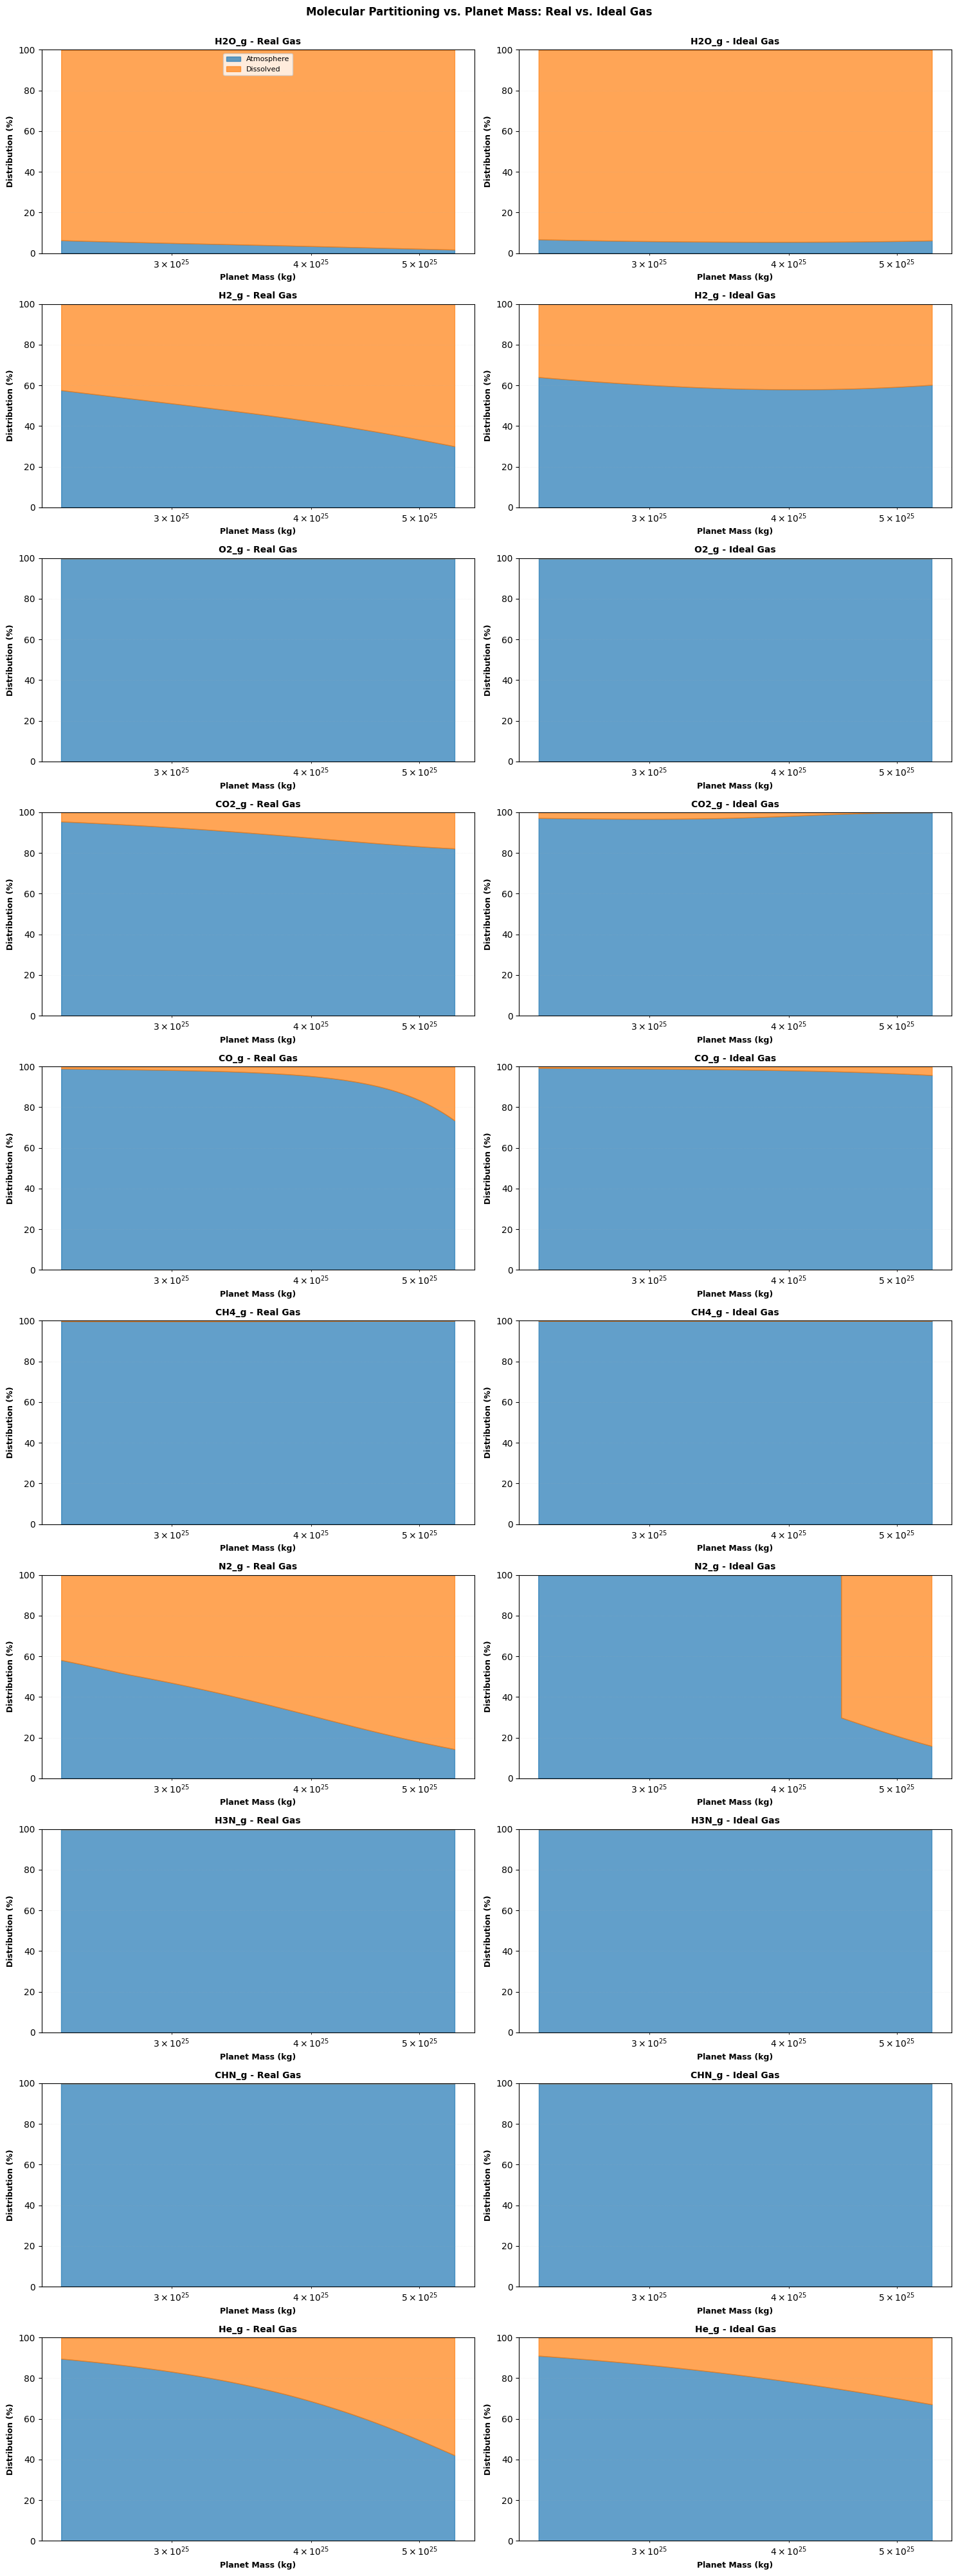

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_gs',
        'H2_gs',
        'O2_g',
        'CO2_gs',
        'CO_gs',
        'CH4_gs',
        'N2_gs',
        'NH3_g',
        'CHN_g',
        'He_gs',)):
    
    print("\n" + "="*70)
    print("Creating molecular budget plot vs. planet mass (Real vs. Ideal)...")
    print("="*70)
    
    # Load planet mass for both models
    real_planet = pd.read_excel('ColdSubNeptune_varyMASS_REAL.xlsx', sheet_name='planet')
    ideal_planet = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name='planet')
    
    planet_mass_real = real_planet['planet_mass']
    planet_mass_ideal = ideal_planet['planet_mass']
    
    # Create figure: 6 molecules, 2 columns (real vs ideal)
    fig, axes = plt.subplots(10, 2, figsize=(15, 40))
    
    for mol_idx, molecule in enumerate(molecules):
        # REAL GAS (left column)
        ax_real = axes[mol_idx, 0]
        df_real = pd.read_excel('ColdSubNeptune_varyMASS_REAL.xlsx', sheet_name=molecule)
        
        atm_mass_real = df_real.get('atmosphere_mass', pd.Series(np.zeros(len(df_real))))
        dis_mass_real = df_real.get('dissolved_mass', pd.Series(np.zeros(len(df_real))))
        con_mass_real = df_real.get('condensed_mass', pd.Series(np.zeros(len(df_real))))
        
        total_mass_real = atm_mass_real + dis_mass_real + con_mass_real
        total_mass_real[total_mass_real == 0] = np.nan
        
        atm_frac_real = atm_mass_real / total_mass_real * 100
        dis_frac_real = dis_mass_real / total_mass_real * 100
        con_frac_real = con_mass_real / total_mass_real * 100
        
        ax_real.fill_between(planet_mass_real, 0, atm_frac_real, label='Atmosphere', 
                            color='#1f77b4', alpha=0.7)
        ax_real.fill_between(planet_mass_real, atm_frac_real, atm_frac_real + dis_frac_real, 
                            label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_real) > 0:
            ax_real.fill_between(planet_mass_real, atm_frac_real + dis_frac_real, 100, 
                                label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_real.set_xscale('log')
        ax_real.set_ylim(0, 100)
        ax_real.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_real.set_title(f'{molecule} - Real Gas', fontsize=10, fontweight='bold')
        if mol_idx == 0:
            ax_real.legend(loc='best', frameon=True, fontsize=8)
        ax_real.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # IDEAL GAS (right column)
        ax_ideal = axes[mol_idx, 1]
        df_ideal = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name=molecule)
        
        atm_mass_ideal = df_ideal.get('atmosphere_mass', pd.Series(np.zeros(len(df_ideal))))
        dis_mass_ideal = df_ideal.get('dissolved_mass', pd.Series(np.zeros(len(df_ideal))))
        con_mass_ideal = df_ideal.get('condensed_mass', pd.Series(np.zeros(len(df_ideal))))
        
        total_mass_ideal = atm_mass_ideal + dis_mass_ideal + con_mass_ideal
        total_mass_ideal[total_mass_ideal == 0] = np.nan
        
        atm_frac_ideal = atm_mass_ideal / total_mass_ideal * 100
        dis_frac_ideal = dis_mass_ideal / total_mass_ideal * 100
        con_frac_ideal = con_mass_ideal / total_mass_ideal * 100
        
        ax_ideal.fill_between(planet_mass_ideal, 0, atm_frac_ideal, label='Atmosphere', 
                             color='#1f77b4', alpha=0.7)
        ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal, atm_frac_ideal + dis_frac_ideal, 
                             label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_ideal) > 0:
            ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal + dis_frac_ideal, 100, 
                                 label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_ideal.set_xscale('log')
        ax_ideal.set_ylim(0, 100)
        ax_ideal.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_ideal.set_title(f'{molecule} - Ideal Gas', fontsize=10, fontweight='bold')
        ax_ideal.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # Set x-label only on bottom row
        ax_real.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
        ax_ideal.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    
    plt.suptitle('Molecular Partitioning vs. Planet Mass: Real vs. Ideal Gas', 
                 fontsize=12, fontweight='bold', y=1)
    plt.tight_layout()
    plt.savefig('molecular_budget_vs_planet_mass_real_vs_ideal.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png")
    plt.show()

# Run the function
plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_g',
        'H2_g',
        'O2_g',
        'CO2_g',
        'CO_g',
        'CH4_g',
        'N2_g',
        'H3N_g',
        'CHN_g',
        'He_g',))



Creating molecular budget plot vs. planet mass (Real vs. Ideal)...

✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png


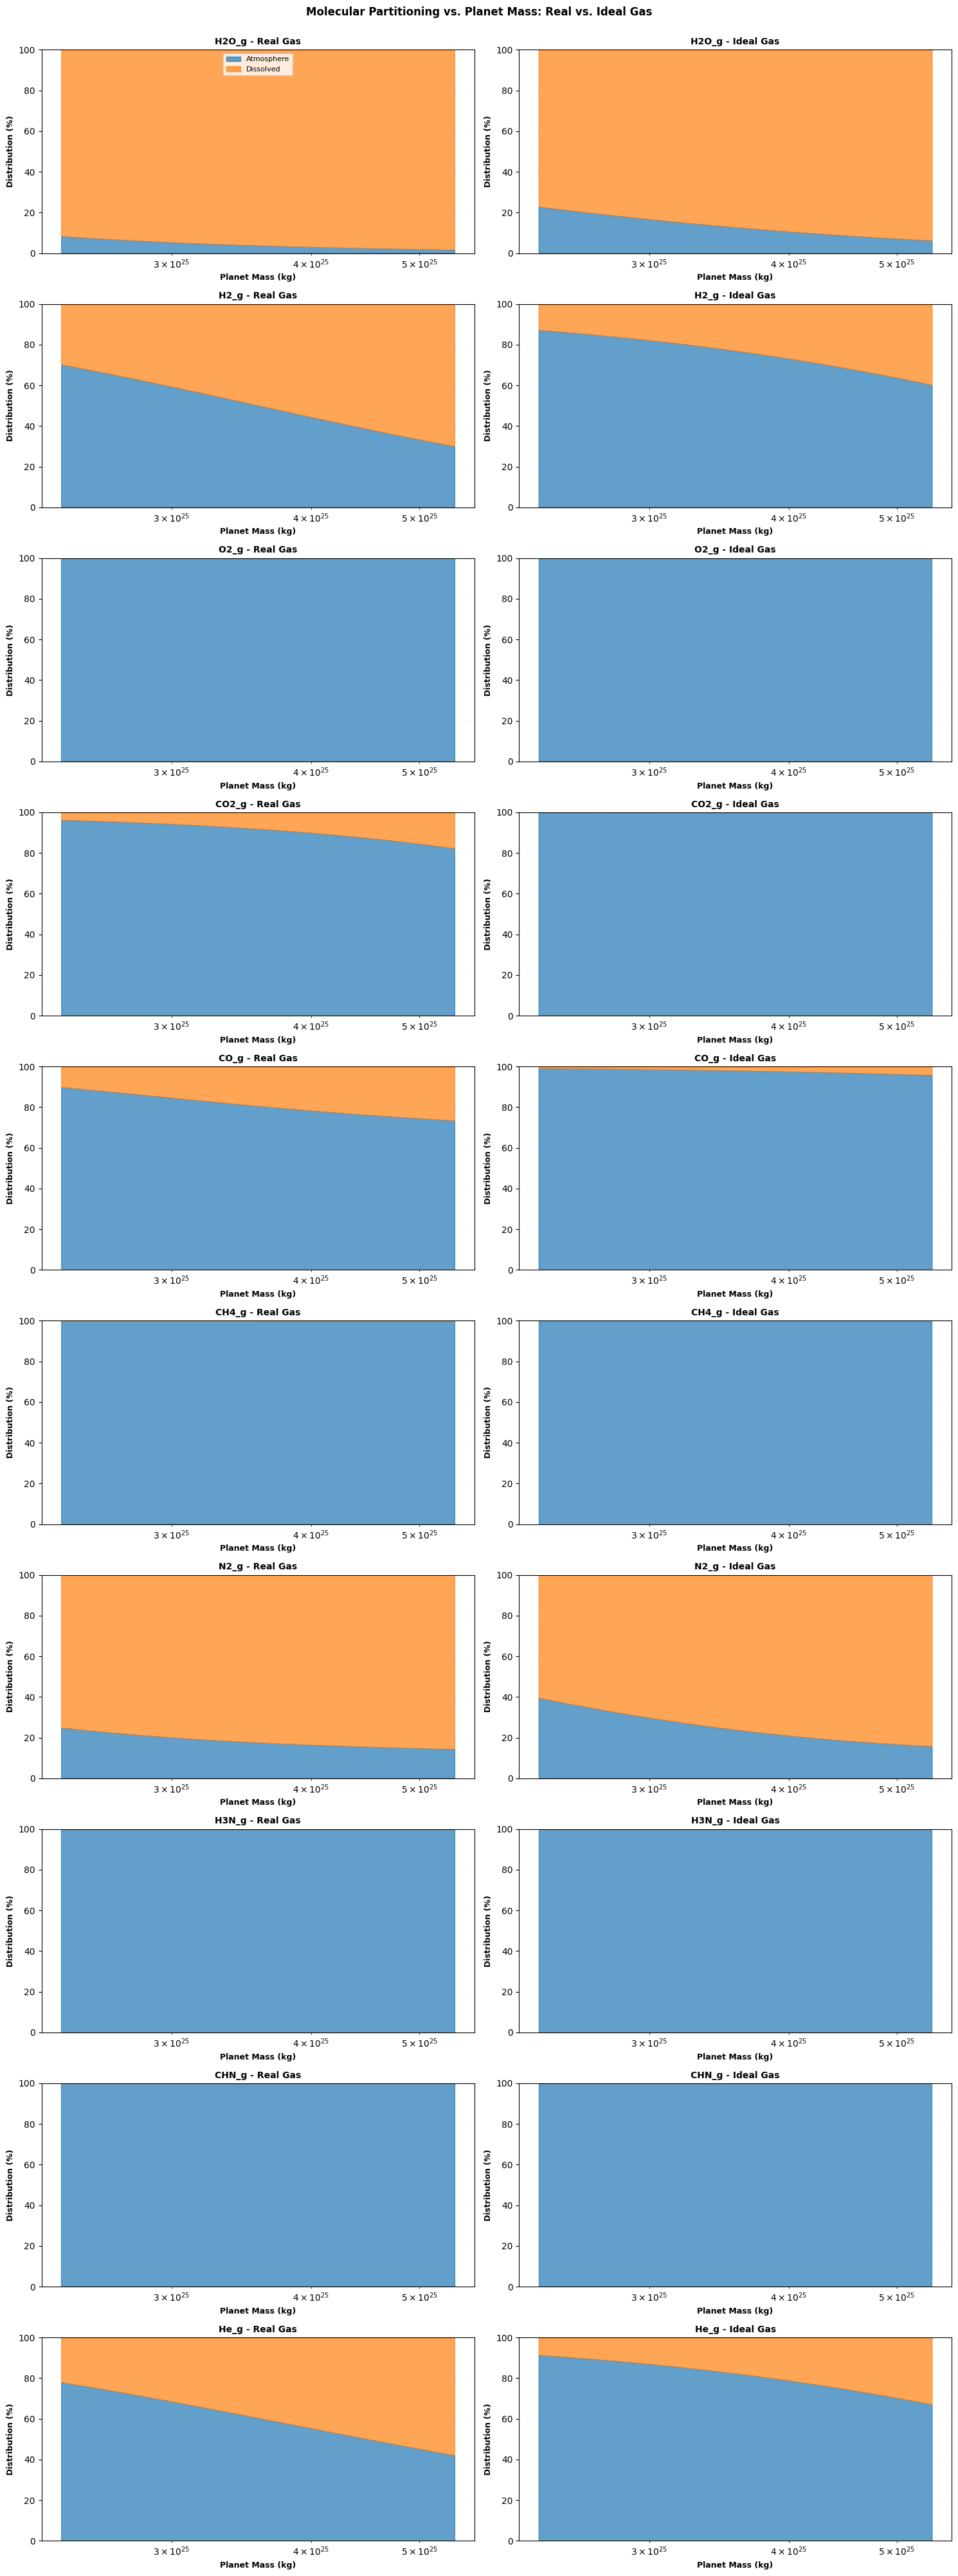

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_gs',
        'H2_gs',
        'O2_g',
        'CO2_gs',
        'CO_gs',
        'CH4_gs',
        'N2_gs',
        'NH3_g',
        'CHN_g',
        'He_gs',)):
    
    print("\n" + "="*70)
    print("Creating molecular budget plot vs. planet mass (Real vs. Ideal)...")
    print("="*70)
    
    # Load planet mass for both models
    real_planet = pd.read_excel('ColdSubNeptune_varyMASS_REAL.xlsx', sheet_name='planet')
    ideal_planet = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name='planet')
    
    planet_mass_real = real_planet['planet_mass']
    planet_mass_ideal = ideal_planet['planet_mass']
    
    # Create figure: 6 molecules, 2 columns (real vs ideal)
    fig, axes = plt.subplots(10, 2, figsize=(15, 40))
    
    for mol_idx, molecule in enumerate(molecules):
        # REAL GAS (left column)
        ax_real = axes[mol_idx, 0]
        df_real = pd.read_excel('ColdSubNeptune_varyMASS_REAL.xlsx', sheet_name=molecule)
        
        atm_mass_real = df_real.get('atmosphere_mass', pd.Series(np.zeros(len(df_real))))
        dis_mass_real = df_real.get('dissolved_mass', pd.Series(np.zeros(len(df_real))))
        con_mass_real = df_real.get('condensed_mass', pd.Series(np.zeros(len(df_real))))
        
        total_mass_real = atm_mass_real + dis_mass_real + con_mass_real
        total_mass_real[total_mass_real == 0] = np.nan
        
        atm_frac_real = atm_mass_real / total_mass_real * 100
        dis_frac_real = dis_mass_real / total_mass_real * 100
        con_frac_real = con_mass_real / total_mass_real * 100
        
        ax_real.fill_between(planet_mass_real, 0, atm_frac_real, label='Atmosphere', 
                            color='#1f77b4', alpha=0.7)
        ax_real.fill_between(planet_mass_real, atm_frac_real, atm_frac_real + dis_frac_real, 
                            label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_real) > 0:
            ax_real.fill_between(planet_mass_real, atm_frac_real + dis_frac_real, 100, 
                                label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_real.set_xscale('log')
        ax_real.set_ylim(0, 100)
        ax_real.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_real.set_title(f'{molecule} - Real Gas', fontsize=10, fontweight='bold')
        if mol_idx == 0:
            ax_real.legend(loc='best', frameon=True, fontsize=8)
        ax_real.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # IDEAL GAS (right column)
        ax_ideal = axes[mol_idx, 1]
        df_ideal = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name=molecule)
        
        atm_mass_ideal = df_ideal.get('atmosphere_mass', pd.Series(np.zeros(len(df_ideal))))
        dis_mass_ideal = df_ideal.get('dissolved_mass', pd.Series(np.zeros(len(df_ideal))))
        con_mass_ideal = df_ideal.get('condensed_mass', pd.Series(np.zeros(len(df_ideal))))
        
        total_mass_ideal = atm_mass_ideal + dis_mass_ideal + con_mass_ideal
        total_mass_ideal[total_mass_ideal == 0] = np.nan
        
        atm_frac_ideal = atm_mass_ideal / total_mass_ideal * 100
        dis_frac_ideal = dis_mass_ideal / total_mass_ideal * 100
        con_frac_ideal = con_mass_ideal / total_mass_ideal * 100
        
        ax_ideal.fill_between(planet_mass_ideal, 0, atm_frac_ideal, label='Atmosphere', 
                             color='#1f77b4', alpha=0.7)
        ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal, atm_frac_ideal + dis_frac_ideal, 
                             label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac_ideal) > 0:
            ax_ideal.fill_between(planet_mass_ideal, atm_frac_ideal + dis_frac_ideal, 100, 
                                 label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax_ideal.set_xscale('log')
        ax_ideal.set_ylim(0, 100)
        ax_ideal.set_ylabel('Distribution (%)', fontsize=9, fontweight='bold')
        ax_ideal.set_title(f'{molecule} - Ideal Gas', fontsize=10, fontweight='bold')
        ax_ideal.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        # Set x-label only on bottom row
        ax_real.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
        ax_ideal.set_xlabel('Planet Mass (kg)', fontsize=9, fontweight='bold')
    
    plt.suptitle('Molecular Partitioning vs. Planet Mass: Real vs. Ideal Gas', 
                 fontsize=12, fontweight='bold', y=1)
    plt.tight_layout()
    plt.savefig('molecular_budget_vs_planet_mass_real_vs_ideal.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: molecular_budget_vs_planet_mass_real_vs_ideal.png")
    plt.show()

# Run the function
plot_molecular_budget_vs_mp_real_vs_ideal(molecules=('H2O_g',
        'H2_g',
        'O2_g',
        'CO2_g',
        'CO_g',
        'CH4_g',
        'N2_g',
        'H3N_g',
        'CHN_g',
        'He_g',))
